In [1]:
# === 1. Imports & Setup ===
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from pathlib import Path

# --- Setup ---
DATA_DIR = Path("../data/ta-data")

def load_ticker(ticker: str) -> pd.DataFrame:
    """Load TA-enriched CSV for a given ticker."""
    csv_path = DATA_DIR / f"{ticker}.csv"
    df = pd.read_csv(csv_path, parse_dates=["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    return df

# Default: NG.L
ticker = "NG.L"
df = load_ticker(ticker)
df.index = df["Date"]
# --- Filter to last 10 years ---
cutoff_date = pd.Timestamp("2024-10-15")
df = df[df["Date"] >= cutoff_date].reset_index(drop=True)
df.index = df["Date"]

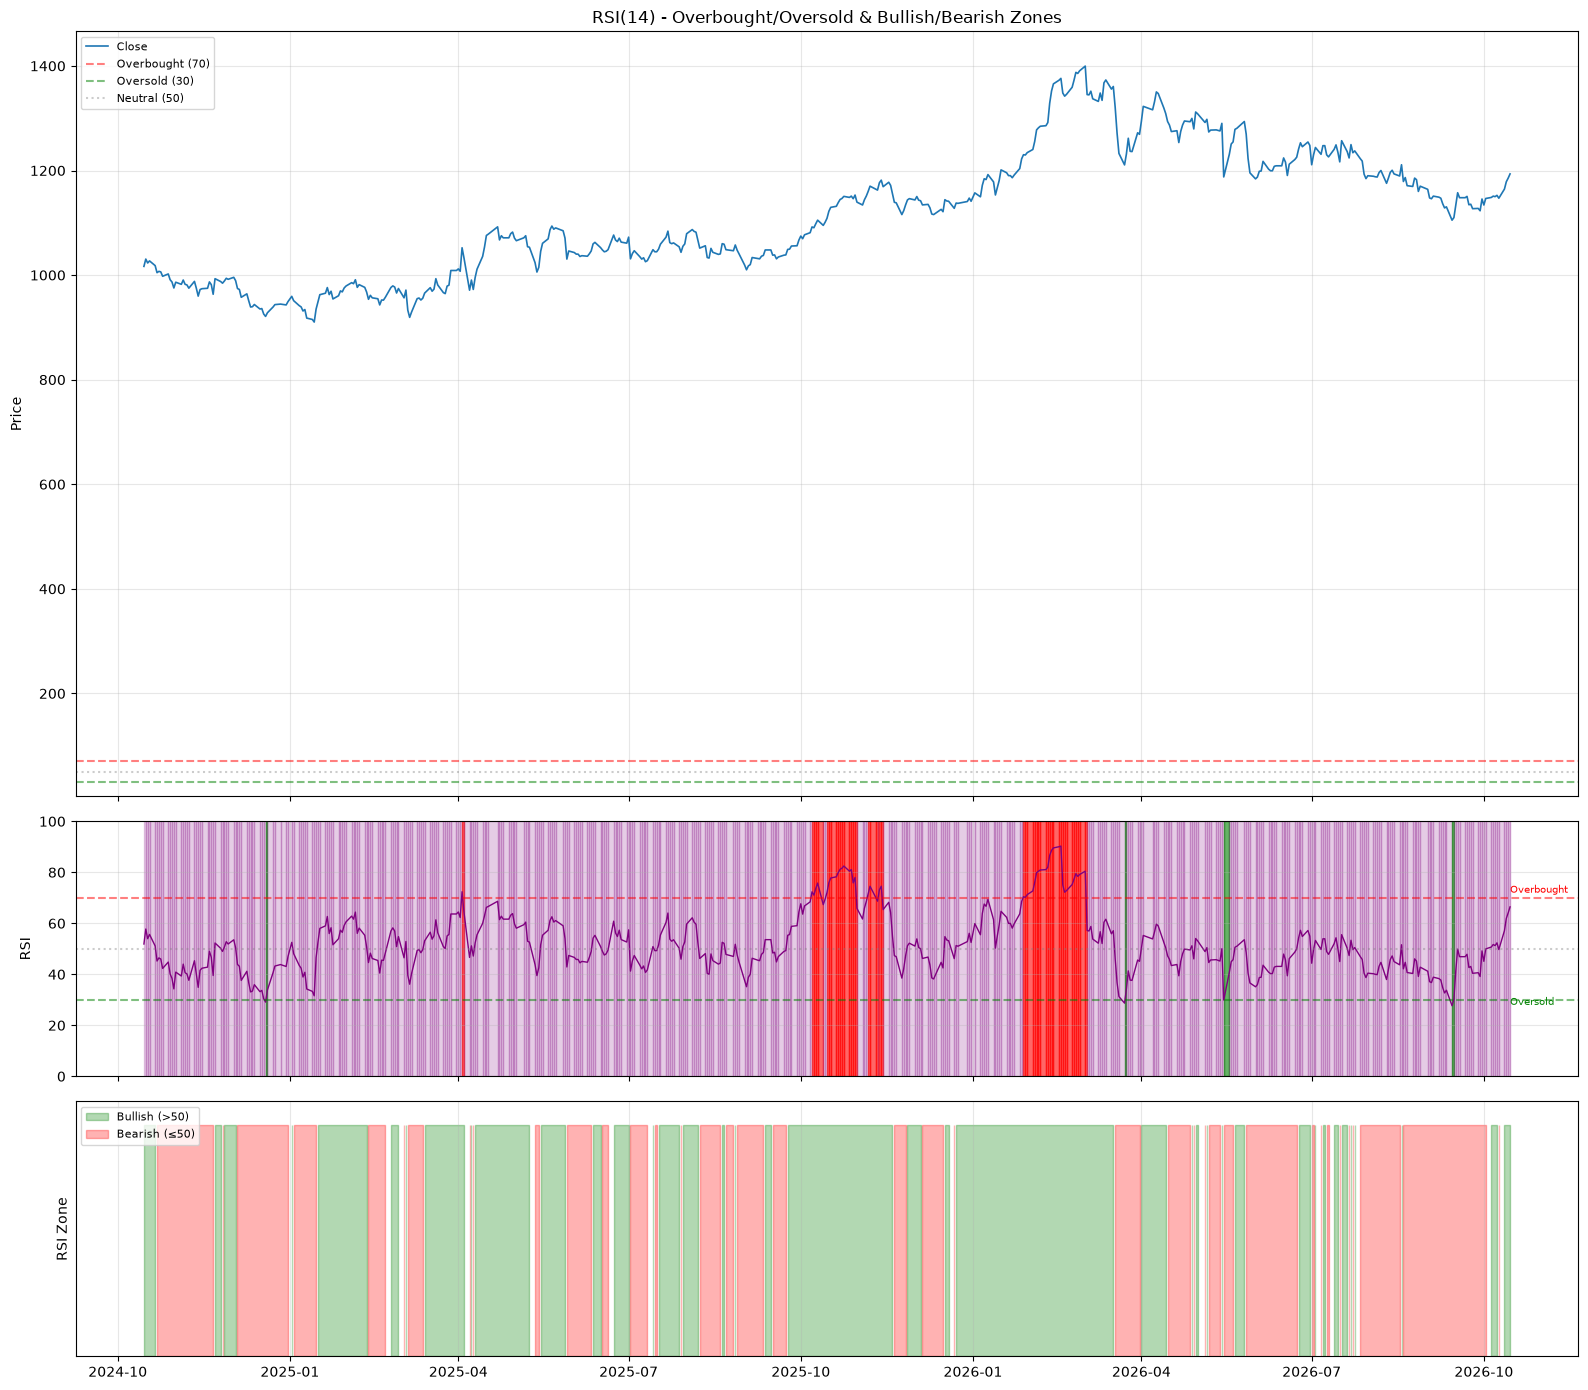

=== RSI(14) Statistics ===
Current RSI: 66.46
Average RSI: 52.09
Min RSI: 27.67
Max RSI: 90.28
Time in Overbought (>70): 9.1%
Time in Oversold (<30): 0.8%
Time Bullish (>50): 51.7%


In [2]:
# === 2. RSI(14) Analysis ===
fig, axes = plt.subplots(3, 1, figsize=(16, 14), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1, 1]})

# Price + RSI overlay
axes[0].plot(df.index, df['Close'], label='Close', linewidth=1.2)
axes[0].axhline(y=70, color='r', linestyle='--', alpha=0.5, label='Overbought (70)')
axes[0].axhline(y=30, color='g', linestyle='--', alpha=0.5, label='Oversold (30)')
axes[0].axhline(y=50, color='gray', linestyle=':', alpha=0.4, label='Neutral (50)')
axes[0].set_ylabel('Price')
axes[0].set_title('RSI(14) - Overbought/Oversold & Bullish/Bearish Zones')
axes[0].legend(loc='upper left', fontsize=8)
axes[0].grid(True, alpha=0.3)

# RSI panel
axes[1].plot(df.index, df['ta_rsi14'], color='purple', linewidth=1)
axes[1].axhline(y=70, color='r', linestyle='--', alpha=0.5)
axes[1].axhline(y=30, color='g', linestyle='--', alpha=0.5)
axes[1].axhline(y=50, color='gray', linestyle=':', alpha=0.4)
axes[1].set_ylabel('RSI')
axes[1].set_ylim(0, 100)
axes[1].grid(True, alpha=0.3)
axes[1].text(df.index[-1], 72, 'Overbought', fontsize=7, color='red')
axes[1].text(df.index[-1], 28, 'Oversold', fontsize=7, color='green')

# RSI color-coded zones
for i in range(len(df)):
    rsi = df['ta_rsi14'].iloc[i]
    color = 'red' if rsi > 70 else ('green' if rsi < 30 else 'purple')
    alpha = 0.6 if rsi > 70 or rsi < 30 else 0.2
    axes[1].axvspan(df.index[i], df.index[min(i+1, len(df)-1)],
                    color=color, alpha=alpha)

# Above/Below 50
axes[2].fill_between(df.index, 0, 1, where=df['ta_rsi14'] > 50,
                     color='green', alpha=0.3, label='Bullish (>50)')
axes[2].fill_between(df.index, 0, 1, where=df['ta_rsi14'] <= 50,
                     color='red', alpha=0.3, label='Bearish (≤50)')
axes[2].set_ylabel('RSI Zone')
axes[2].set_ylim(0, 1.1)
axes[2].set_yticks([])
axes[2].legend(loc='upper left', fontsize=8)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Statistics
print("=== RSI(14) Statistics ===")
print(f"Current RSI: {df['ta_rsi14'].iloc[-1]:.2f}")
print(f"Average RSI: {df['ta_rsi14'].mean():.2f}")
print(f"Min RSI: {df['ta_rsi14'].min():.2f}")
print(f"Max RSI: {df['ta_rsi14'].max():.2f}")
print(f"Time in Overbought (>70): {(df['ta_rsi14'] > 70).mean()*100:.1f}%")
print(f"Time in Oversold (<30): {(df['ta_rsi14'] < 30).mean()*100:.1f}%")
print(f"Time Bullish (>50): {(df['ta_rsi14'] > 50).mean()*100:.1f}%")

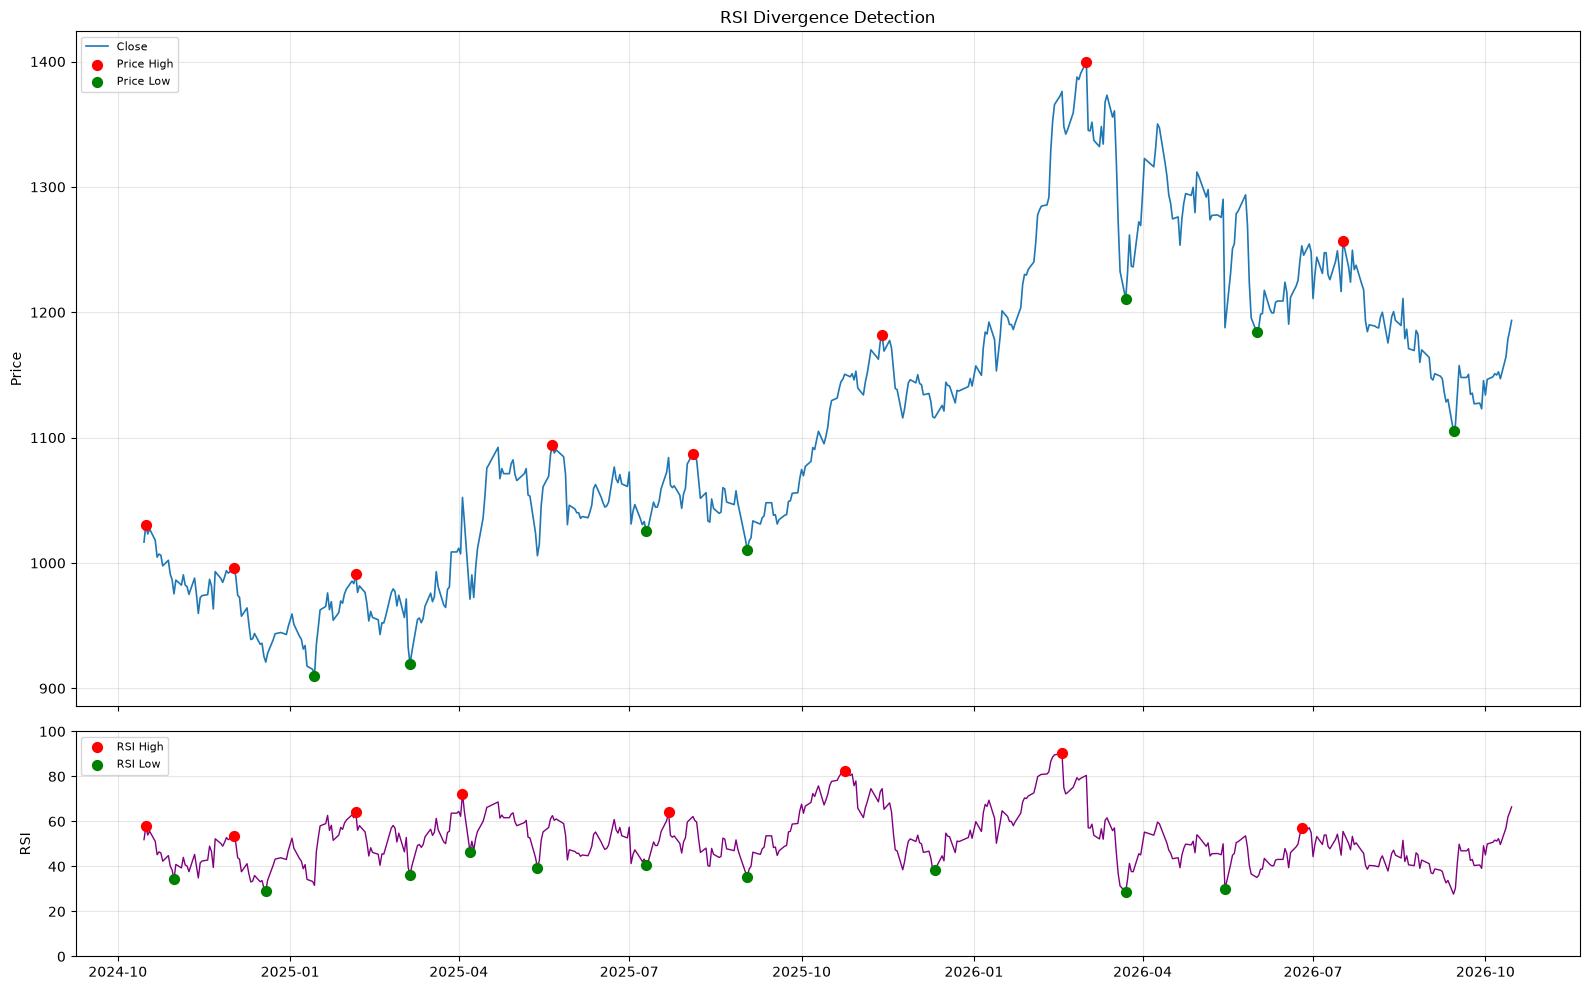

=== Divergence Analysis ===
  No clear divergences detected in recent history.


In [3]:
# === 3. RSI Divergence Detection ===
from scipy.signal import argrelextrema

# Find local extrema
order = 20
high_idx = argrelextrema(df['Close'].values, np.greater, order=order)[0]
low_idx = argrelextrema(df['Close'].values, np.less, order=order)[0]
rsi_high_idx = argrelextrema(df['ta_rsi14'].values, np.greater, order=order)[0]
rsi_low_idx = argrelextrema(df['ta_rsi14'].values, np.less, order=order)[0]

fig, ax = plt.subplots(2, 1, figsize=(16, 10), sharex=True,
                       gridspec_kw={'height_ratios': [3, 1]})

# Price
ax[0].plot(df.index, df['Close'], label='Close', linewidth=1.2)
for i in high_idx[:10]:
    ax[0].scatter(df.index[i], df['Close'].iloc[i], color='red', s=50, zorder=5, label='Price High' if i == high_idx[0] else "")
for i in low_idx[:10]:
    ax[0].scatter(df.index[i], df['Close'].iloc[i], color='green', s=50, zorder=5, label='Price Low' if i == low_idx[0] else "")
ax[0].set_ylabel('Price')
ax[0].set_title('RSI Divergence Detection')
ax[0].legend(loc='upper left', fontsize=8)
ax[0].grid(True, alpha=0.3)

# RSI
ax[1].plot(df.index, df['ta_rsi14'], color='purple', linewidth=1)
for i in rsi_high_idx[:10]:
    ax[1].scatter(df.index[i], df['ta_rsi14'].iloc[i], color='red', s=50, zorder=5, label='RSI High' if i == rsi_high_idx[0] else "")
for i in rsi_low_idx[:10]:
    ax[1].scatter(df.index[i], df['ta_rsi14'].iloc[i], color='green', s=50, zorder=5, label='RSI Low' if i == rsi_low_idx[0] else "")
ax[1].set_ylabel('RSI')
ax[1].set_ylim(0, 100)
ax[1].grid(True, alpha=0.3)
ax[1].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

# Detect divergences
print("=== Divergence Analysis ===")
divergences = []
for hi in high_idx[1:]:
    for prev_hi in high_idx[:hi]:
        if df['Close'].iloc[hi] > df['Close'].iloc[prev_hi]:
            # Check if RSI made lower high
            for rhi in rsi_high_idx:
                if prev_hi < rhi < hi:
                    rhi_prev = None
                    for rhp in rsi_high_idx:
                        if rhp < prev_hi:
                            rhi_prev = rhp
                    if rhi_prev and df['ta_rsi14'].iloc[rhi] < df['ta_rsi14'].iloc[rhi_prev]:
                        divergences.append(('Bearish', df.index[prev_hi], df.index[hi]))
                        break
            break

for li in low_idx[1:]:
    for prev_li in low_idx[:li]:
        if df['Close'].iloc[li] < df['Close'].iloc[prev_li]:
            for rli in rsi_low_idx:
                if prev_li < rli < li:
                    rli_prev = None
                    for rlp in rsi_low_idx:
                        if rlp < prev_li:
                            rli_prev = rlp
                    if rli_prev and df['ta_rsi14'].iloc[rli] > df['ta_rsi14'].iloc[rli_prev]:
                        divergences.append(('Bullish', df.index[prev_li], df.index[li]))
                        break
            break

if divergences:
    for div_type, start, end in divergences[-5:]:
        print(f"  {div_type} Divergence: {start.date()} → {end.date()}")
else:
    print("  No clear divergences detected in recent history.")

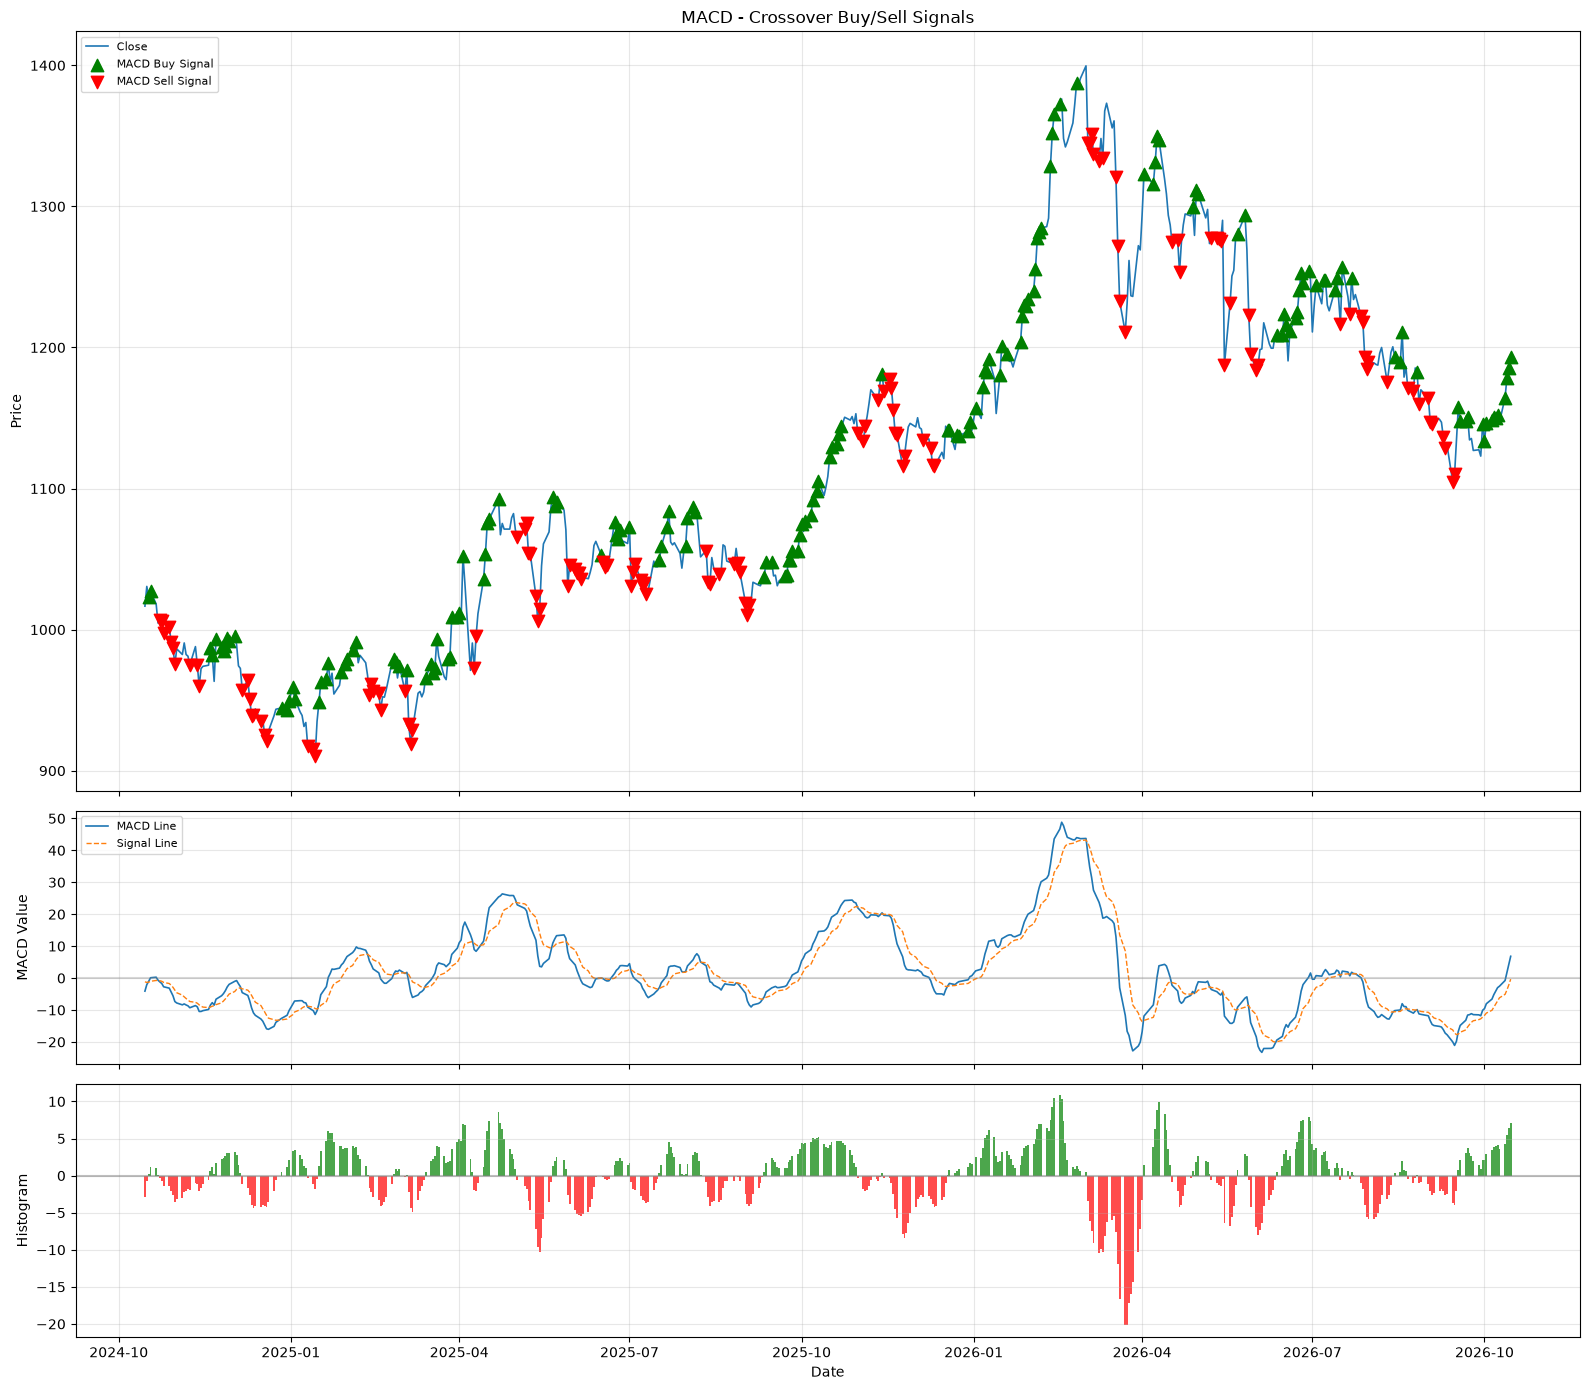

=== MACD Statistics ===
Current MACD Line: 6.8228
Current Signal: -0.3365
Current Histogram: 7.1594
MACD > Signal (Bullish): 53.6%
MACD > 0: 48.1%
Total Buy Signals (crossover): 160
Total Sell Signals (crossover): 123


In [4]:
# === 4. MACD Analysis ===
fig, axes = plt.subplots(3, 1, figsize=(16, 14), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1, 1]})

# Price + MACD signal markers
axes[0].plot(df.index, df['Close'], label='Close', linewidth=1.2)
# Buy signals: MACD crosses above Signal
buy_mask = (df['ta_macd_line'] > df['ta_macd_signal']) & (df['ta_macd_line'].diff() > df['ta_macd_signal'].diff())
sell_mask = (df['ta_macd_line'] < df['ta_macd_signal']) & (df['ta_macd_line'].diff() < df['ta_macd_signal'].diff())

axes[0].scatter(df.index[buy_mask], df['Close'][buy_mask], marker='^', color='green',
                s=80, zorder=5, label='MACD Buy Signal')
axes[0].scatter(df.index[sell_mask], df['Close'][sell_mask], marker='v', color='red',
                s=80, zorder=5, label='MACD Sell Signal')
axes[0].set_ylabel('Price')
axes[0].set_title('MACD - Crossover Buy/Sell Signals')
axes[0].legend(loc='upper left', fontsize=8)
axes[0].grid(True, alpha=0.3)

# MACD Line, Signal Line
axes[1].plot(df.index, df['ta_macd_line'], label='MACD Line', linewidth=1.2)
axes[1].plot(df.index, df['ta_macd_signal'], label='Signal Line', linewidth=1, linestyle='--')
axes[1].axhline(y=0, color='gray', linestyle='-', alpha=0.3)
axes[1].set_ylabel('MACD Value')
axes[1].legend(loc='upper left', fontsize=8)
axes[1].grid(True, alpha=0.3)

# Histogram
colors = ['green' if v >= 0 else 'red' for v in df['ta_macd_histogram']]
axes[2].bar(df.index, df['ta_macd_histogram'], color=colors, alpha=0.7, width=1)
axes[2].axhline(y=0, color='gray', linestyle='-', alpha=0.5)
axes[2].set_ylabel('Histogram')
axes[2].set_xlabel('Date')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Statistics
print("=== MACD Statistics ===")
print(f"Current MACD Line: {df['ta_macd_line'].iloc[-1]:.4f}")
print(f"Current Signal: {df['ta_macd_signal'].iloc[-1]:.4f}")
print(f"Current Histogram: {df['ta_macd_histogram'].iloc[-1]:.4f}")
print(f"MACD > Signal (Bullish): {(df['ta_macd_line'] > df['ta_macd_signal']).mean()*100:.1f}%")
print(f"MACD > 0: {(df['ta_macd_line'] > 0).mean()*100:.1f}%")
print(f"Total Buy Signals (crossover): {buy_mask.sum()}")
print(f"Total Sell Signals (crossover): {sell_mask.sum()}")

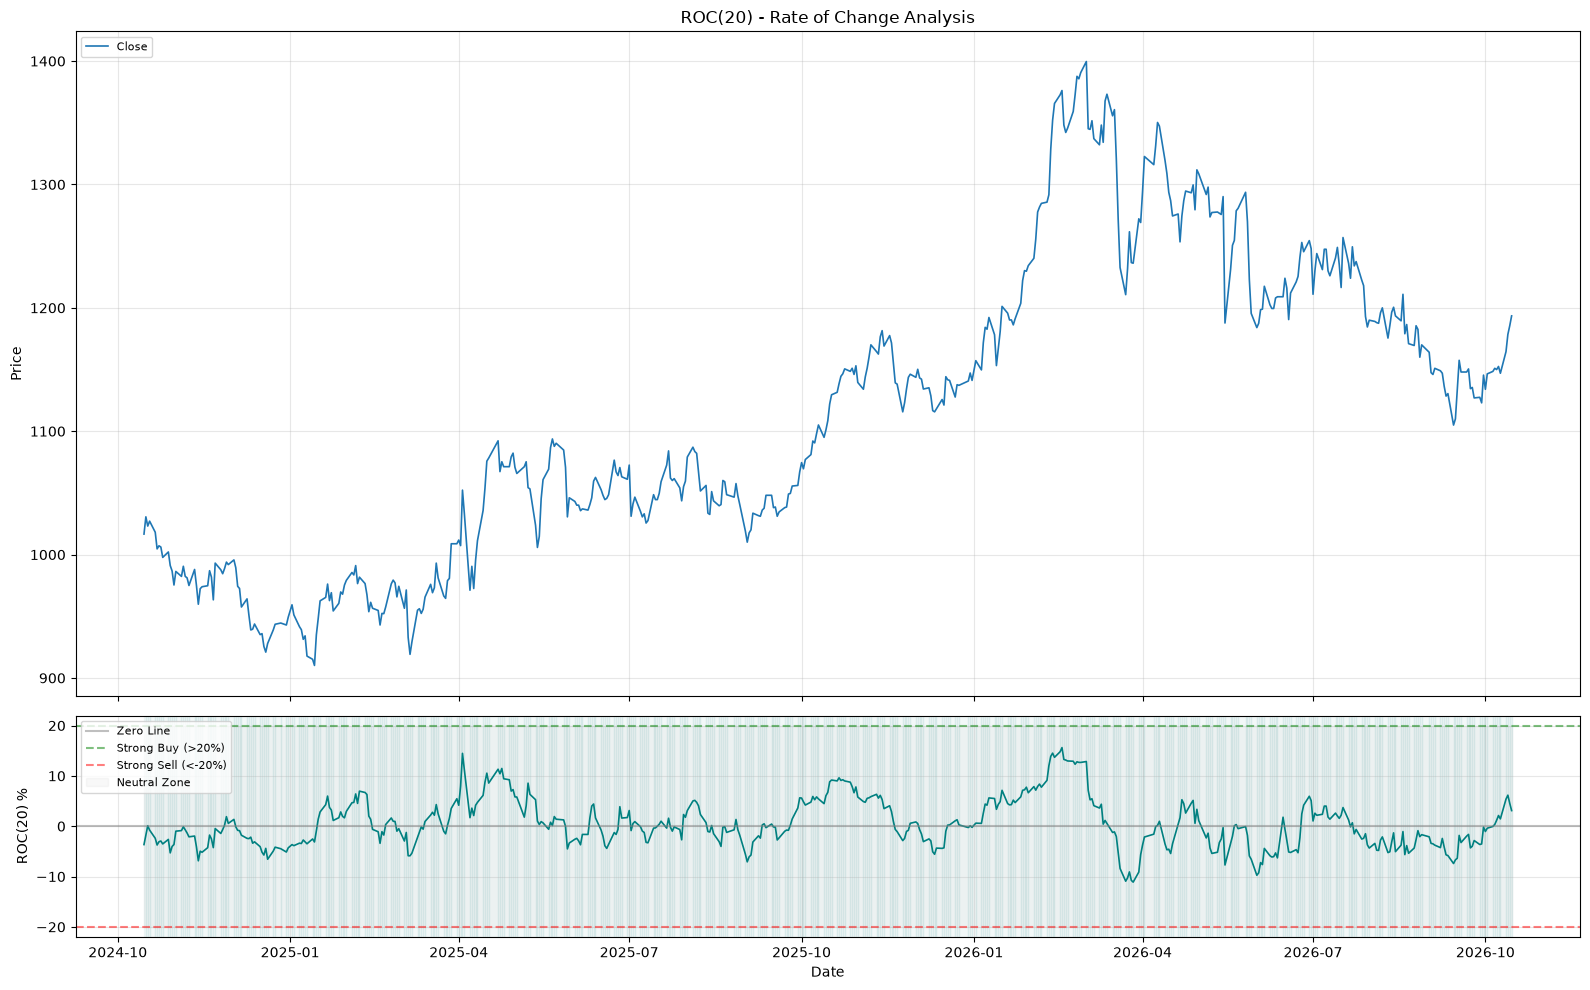

=== ROC(20) Statistics ===
Current ROC: 3.11%
Average ROC: 0.58%
Min ROC: -11.11%
Max ROC: 15.62%
ROC > 0 (Positive): 48.3%
ROC > 20% (Strong Bullish): 0.0%
ROC < -20% (Strong Bearish): 0.0%


In [5]:
# === 5. ROC(20) Analysis ===
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]})

# Price
axes[0].plot(df.index, df['Close'], label='Close', linewidth=1.2)
# ROC crossover signals
roc_buy = (df['ta_roc20'] > 0) & (df['ta_roc20'].diff() > 0)  # simplified
axes[0].set_ylabel('Price')
axes[0].set_title('ROC(20) - Rate of Change Analysis')
axes[0].legend(loc='upper left', fontsize=8)
axes[0].grid(True, alpha=0.3)

# ROC with zones
axes[1].plot(df.index, df['ta_roc20'], color='teal', linewidth=1.2)
axes[1].axhline(y=0, color='gray', linestyle='-', alpha=0.5, label='Zero Line')
axes[1].axhline(y=20, color='green', linestyle='--', alpha=0.5, label='Strong Buy (>20%)')
axes[1].axhline(y=-20, color='red', linestyle='--', alpha=0.5, label='Strong Sell (<-20%)')

# Color zones
for i in range(len(df)):
    roc = df['ta_roc20'].iloc[i]
    color = 'green' if roc > 20 else ('red' if roc < -20 else 'teal')
    alpha = 0.3 if abs(roc) > 20 else 0.05
    axes[1].axvspan(df.index[i], df.index[min(i+1, len(df)-1)],
                    color=color, alpha=alpha)

axes[1].fill_between(df.index, -20, 20, alpha=0.05, color='gray', label='Neutral Zone')
axes[1].set_ylabel('ROC(20) %')
axes[1].legend(loc='upper left', fontsize=8)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlabel('Date')

plt.tight_layout()
plt.show()

# Statistics
print("=== ROC(20) Statistics ===")
print(f"Current ROC: {df['ta_roc20'].iloc[-1]:.2f}%")
print(f"Average ROC: {df['ta_roc20'].mean():.2f}%")
print(f"Min ROC: {df['ta_roc20'].min():.2f}%")
print(f"Max ROC: {df['ta_roc20'].max():.2f}%")
print(f"ROC > 0 (Positive): {(df['ta_roc20'] > 0).mean()*100:.1f}%")
print(f"ROC > 20% (Strong Bullish): {(df['ta_roc20'] > 20).mean()*100:.1f}%")
print(f"ROC < -20% (Strong Bearish): {(df['ta_roc20'] < -20).mean()*100:.1f}%")

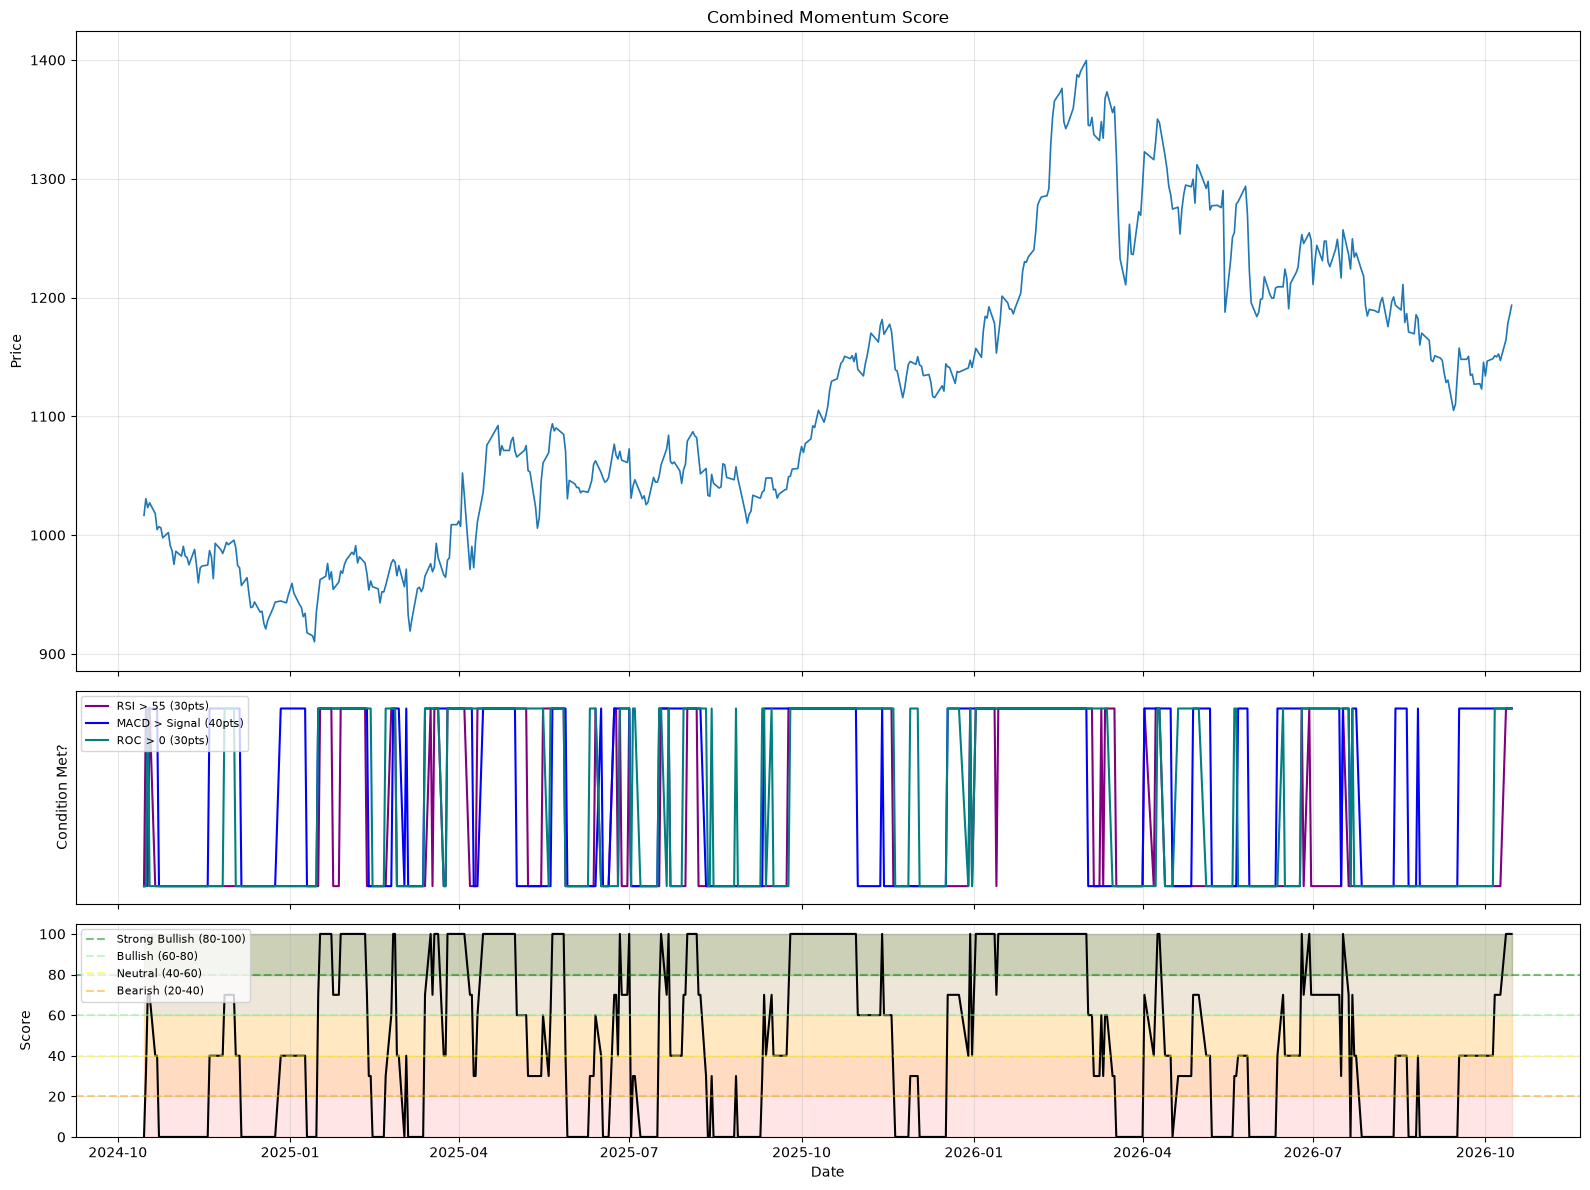

=== Momentum Score Distribution ===
  Strong Bullish       ( 80-100):     0 days (  0.0%)
  Bullish              ( 60- 80):    85 days ( 16.8%)
  Neutral              ( 40- 60):    82 days ( 16.2%)
  Bearish              ( 20- 40):    40 days (  7.9%)
  Strong Bearish       (  0- 20):   169 days ( 33.3%)

Current Score: 100/100


In [6]:
# === 6. Combined Momentum Score ===
# Based on scoring model from momentum_indicator.md

df['momentum_score'] = 0
df['momentum_score'] += (df['ta_rsi14'] > 55).astype(int) * 30
df['momentum_score'] += (df['ta_macd_line'] > df['ta_macd_signal']).astype(int) * 40
df['momentum_score'] += (df['ta_roc20'] > 0).astype(int) * 30

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1, 1]})

# Price
axes[0].plot(df.index, df['Close'], label='Close', linewidth=1.2)
axes[0].set_ylabel('Price')
axes[0].set_title('Combined Momentum Score')
axes[0].grid(True, alpha=0.3)

# Individual indicator contributions
axes[1].plot(df.index, df['ta_rsi14'] > 55, color='purple', linewidth=1.5, label='RSI > 55 (30pts)')
axes[1].plot(df.index, df['ta_macd_line'] > df['ta_macd_signal'], color='blue', linewidth=1.5, label='MACD > Signal (40pts)')
axes[1].plot(df.index, df['ta_roc20'] > 0, color='teal', linewidth=1.5, label='ROC > 0 (30pts)')
axes[1].set_ylim(-0.1, 1.1)
axes[1].set_ylabel('Condition Met?')
axes[1].legend(loc='upper left', fontsize=8)
axes[1].grid(True, alpha=0.3)
axes[1].set_yticks([])

# Total score
score_colors = ['red' if s < 20 else ('orange' if s < 40 else ('yellow' if s < 60 else ('lightgreen' if s < 80 else 'green')))
                for s in df['momentum_score']]
axes[2].fill_between(df.index, 0, 100, alpha=0.1, color='red')
axes[2].fill_between(df.index, 20, 40, alpha=0.15, color='orange')
axes[2].fill_between(df.index, 40, 60, alpha=0.15, color='yellow')
axes[2].fill_between(df.index, 60, 80, alpha=0.15, color='lightgreen')
axes[2].fill_between(df.index, 80, 100, alpha=0.2, color='green')

axes[2].plot(df.index, df['momentum_score'], color='black', linewidth=1.5)
axes[2].set_ylabel('Score')
axes[2].set_ylim(0, 105)
axes[2].set_yticks([0, 20, 40, 60, 80, 100])
axes[2].axhline(y=80, color='green', linestyle='--', alpha=0.5, label='Strong Bullish (80-100)')
axes[2].axhline(y=60, color='lightgreen', linestyle='--', alpha=0.5, label='Bullish (60-80)')
axes[2].axhline(y=40, color='yellow', linestyle='--', alpha=0.5, label='Neutral (40-60)')
axes[2].axhline(y=20, color='orange', linestyle='--', alpha=0.5, label='Bearish (20-40)')
axes[2].legend(loc='upper left', fontsize=8)
axes[2].grid(True, alpha=0.3)
axes[2].set_xlabel('Date')

plt.tight_layout()
plt.show()

# Classification counts
bins = [(80, 100, 'Strong Bullish'), (60, 80, 'Bullish'), (40, 60, 'Neutral'),
        (20, 40, 'Bearish'), (0, 20, 'Strong Bearish')]
print("=== Momentum Score Distribution ===")
for lo, hi, label in bins:
    count = ((df['momentum_score'] >= lo) & (df['momentum_score'] < hi)).sum()
    pct = count / len(df) * 100
    print(f"  {label:20s} ({lo:3d}-{hi:3d}): {count:5d} days ({pct:5.1f}%)")

print(f"\nCurrent Score: {df['momentum_score'].iloc[-1]:.0f}/100")

/tmp/ipykernel_13015/3570213080.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_roc.legend(loc='upper left', fontsize=9)


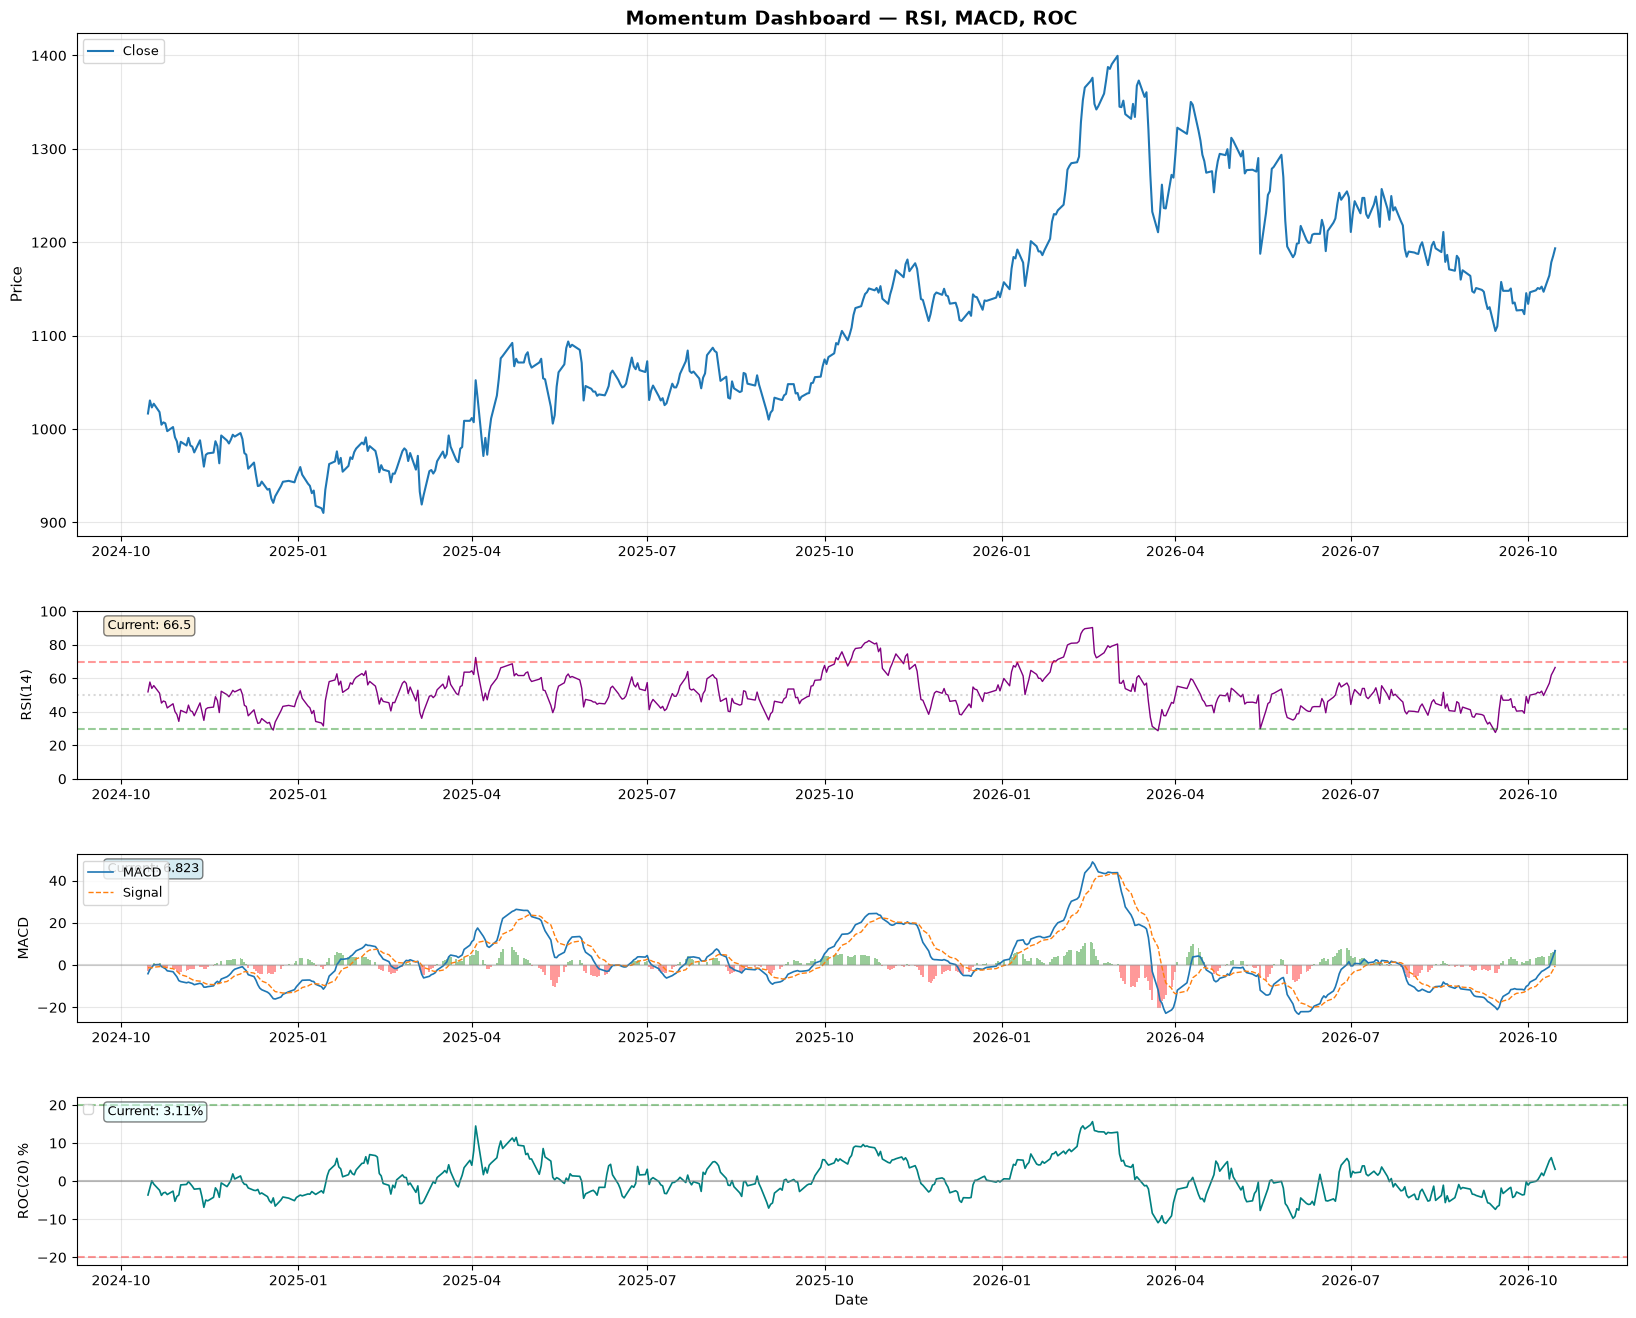

In [7]:
# === 7. Full Momentum Dashboard ===
fig = plt.figure(figsize=(20, 16))
gs = fig.add_gridspec(4, 1, height_ratios=[3, 1, 1, 1], hspace=0.3)

ax_price = fig.add_subplot(gs[0])
ax_rsi = fig.add_subplot(gs[1], sharex=ax_price)
ax_macd = fig.add_subplot(gs[2], sharex=ax_price)
ax_roc = fig.add_subplot(gs[3], sharex=ax_price)

# Price
ax_price.plot(df.index, df['Close'], label='Close', linewidth=1.5)
ax_price.set_ylabel('Price', fontsize=11)
ax_price.set_title('Momentum Dashboard — RSI, MACD, ROC', fontsize=14, fontweight='bold')
ax_price.legend(loc='upper left', fontsize=9)
ax_price.grid(True, alpha=0.3)

# RSI
colors_rsi = ['red' if v > 70 else ('green' if v < 30 else 'purple') for v in df['ta_rsi14']]
ax_rsi.plot(df.index, df['ta_rsi14'], color='purple', linewidth=1)
ax_rsi.axhline(y=70, color='r', linestyle='--', alpha=0.4)
ax_rsi.axhline(y=30, color='g', linestyle='--', alpha=0.4)
ax_rsi.axhline(y=50, color='gray', linestyle=':', alpha=0.3)
ax_rsi.set_ylabel('RSI(14)', fontsize=10)
ax_rsi.set_ylim(0, 100)
ax_rsi.grid(True, alpha=0.3)
ax_rsi.text(0.02, 0.95, f'Current: {df["ta_rsi14"].iloc[-1]:.1f}',
            transform=ax_rsi.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# MACD
ax_macd.plot(df.index, df['ta_macd_line'], label='MACD', linewidth=1.2)
ax_macd.plot(df.index, df['ta_macd_signal'], label='Signal', linewidth=1, linestyle='--')
hist_colors = ['green' if v >= 0 else 'red' for v in df['ta_macd_histogram']]
ax_macd.bar(df.index, df['ta_macd_histogram'], color=hist_colors, alpha=0.4, width=1)
ax_macd.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
ax_macd.set_ylabel('MACD', fontsize=10)
ax_macd.legend(loc='upper left', fontsize=9)
ax_macd.grid(True, alpha=0.3)
ax_macd.text(0.02, 0.95, f'Current: {df["ta_macd_line"].iloc[-1]:.3f}',
            transform=ax_macd.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

# ROC
ax_roc.plot(df.index, df['ta_roc20'], color='teal', linewidth=1.2)
ax_roc.axhline(y=0, color='gray', linestyle='-', alpha=0.5)
ax_roc.axhline(y=20, color='g', linestyle='--', alpha=0.4)
ax_roc.axhline(y=-20, color='r', linestyle='--', alpha=0.4)
ax_roc.set_ylabel('ROC(20) %', fontsize=10)
ax_roc.set_xlabel('Date', fontsize=10)
ax_roc.legend(loc='upper left', fontsize=9)
ax_roc.grid(True, alpha=0.3)
ax_roc.text(0.02, 0.95, f'Current: {df["ta_roc20"].iloc[-1]:.2f}%',
            transform=ax_roc.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightcyan', alpha=0.5))

plt.show()